# fast-wigner-d: example usage

Wigner $d$- and $D$-matrices for any spin $j = 0, \tfrac12, 1, \dots$ and any real angle, in the conventions of
Varshalovich, Moskalev & Khersonskii, *Quantum Theory of Angular Momentum* (1988), Ch. 4:

$$
D^j_{m'm}(\alpha,\beta,\gamma) = \langle j m' |\, e^{-i\alpha J_z} e^{-i\beta J_y} e^{-i\gamma J_z} \,| j m\rangle
= e^{-i m'\alpha}\, d^j_{m'm}(\beta)\, e^{-i m\gamma}.
$$

Matrices are indexed as `d[m' + j, m + j]`, with $m = -j, \dots, j$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import fast_wigner_d as fwd
from fast_wigner_d import wigner_d, wigner_D

np.set_printoptions(precision=6, suppress=True, linewidth=110)
print(f"fast-wigner-d {fwd.__version__}, OpenMP enabled: {fwd.OPENMP_ENABLED}")

fast-wigner-d 0.1.0, OpenMP enabled: True


## 1. Small-$d$ matrices

`j` can be an `int`, a `float` (`0.5`, `1.5`) or a `Fraction`. For $j=\tfrac12$, row 0 is $m'=-\tfrac12$, so the lower-left
entry is $d^{1/2}_{1/2,-1/2} = -\sin\frac\beta2$.

In [2]:
beta = 0.83
c, s = np.cos(beta / 2), np.sin(beta / 2)

d_half = wigner_d(1/2, beta)
print(d_half)
assert np.allclose(d_half, [[c, s], [-s, c]])

# j = 1 against its closed form (rows/columns m = -1, 0, 1)
cb, sb = np.cos(beta), np.sin(beta) / np.sqrt(2)
closed_form = [[(1 + cb) / 2,  sb, (1 - cb) / 2],
             [-sb,           cb, sb          ],
             [(1 - cb) / 2, -sb, (1 + cb) / 2]]
print(np.abs(wigner_d(1, beta) - closed_form).max())

[[ 0.915116  0.40319 ]
 [-0.40319   0.915116]]
0.0


Element access for integer and half-integer $m$:

In [3]:
def element(d, j, mp, m):
    "d^j_{m'm} from a matrix returned by wigner_d."
    return d[int(round(mp + j)), int(round(m + j))]

j = 3/2
d = wigner_d(j, beta)
print("m =", np.arange(-j, j + 1))
print("d^{3/2}_{3/2,1/2}(beta) =", element(d, j, 3/2, 1/2))
print("-sqrt(3) cos^2 sin      =", -np.sqrt(3) * c**2 * s)

m = [-1.5 -0.5  0.5  1.5]
d^{3/2}_{3/2,1/2}(beta) = -0.5848209285981241
-sqrt(3) cos^2 sin      = -0.5848209285981241


## 2. $D$-matrices

`wigner_D(j, alpha, beta, gamma)` uses z-y-z Euler angles. For half-integer $j$ it changes sign under a $2\pi$ rotation.

In [4]:
alpha, beta, gamma = 0.4, 1.3, -2.2
D = wigner_D(3/2, alpha, beta, gamma)
print("unitary:               ", np.allclose(D @ D.conj().T, np.eye(4)))
print("D(alpha + 2pi) == -D:  ", np.allclose(wigner_D(3/2, alpha + 2 * np.pi, beta, gamma), -D))
print("D(alpha + 4pi) == +D:  ", np.allclose(wigner_D(3/2, alpha + 4 * np.pi, beta, gamma), D))

unitary:                True
D(alpha + 2pi) == -D:   True
D(alpha + 4pi) == +D:   True


For $j=1$, $D^1_{m'm} = e_{m'}^{*}\cdot R\, e_m$ with $R = R_z(\alpha) R_y(\beta) R_z(\gamma)$, $e_{\pm1} = \mp(\hat x \pm i\hat y)/\sqrt2$
and $e_0 = \hat z$, which checks all the sign conventions:

In [5]:
def rz(t):
    return np.array([[np.cos(t), -np.sin(t), 0], [np.sin(t), np.cos(t), 0], [0, 0, 1]])

def ry(t):
    return np.array([[np.cos(t), 0, np.sin(t)], [0, 1, 0], [-np.sin(t), 0, np.cos(t)]])

R = rz(alpha) @ ry(beta) @ rz(gamma)
e = np.array([[1, -1j, 0], [0, 0, np.sqrt(2)], [-1, -1j, 0]]) / np.sqrt(2)   # e_{-1}, e_0, e_{+1}
print(np.abs(wigner_D(1, alpha, beta, gamma) - e.conj() @ R @ e.T).max())

3.510833468576701e-16


## 3. Identities

Any real angle is accepted (negative, $> \pi$, $> 2\pi$):

In [6]:
j, b1, b2 = 7/2, 0.7, -2.1
d1, d2 = wigner_d(j, b1), wigner_d(j, b2)
n = int(2 * j + 1)

checks = {
    "orthogonal: d d^T = 1":              np.abs(d1 @ d1.T - np.eye(n)).max(),
    "group law: d(b1) d(b2) = d(b1+b2)":  np.abs(d1 @ d2 - wigner_d(j, b1 + b2)).max(),
    "d(-b) = d(b)^T":                     np.abs(wigner_d(j, -b1) - d1.T).max(),
    "d(b + 2pi) = (-1)^(2j) d(b)":        np.abs(wigner_d(j, b1 + 2 * np.pi) + d1).max(),
    "d(0) = 1":                           np.abs(wigner_d(j, 0.0) - np.eye(n)).max(),
}
for name, err in checks.items():
    print(f"{name:38s} max deviation {err:.1e}")

orthogonal: d d^T = 1                  max deviation 6.7e-16
group law: d(b1) d(b2) = d(b1+b2)      max deviation 2.8e-16
d(-b) = d(b)^T                         max deviation 0.0e+00
d(b + 2pi) = (-1)^(2j) d(b)            max deviation 0.0e+00
d(0) = 1                               max deviation 0.0e+00


## 4. Arrays of angles

An array `beta` gives shape `beta.shape + (2j+1, 2j+1)`. Below: the $4\pi$ period of half-integer spin, and the orthogonality
relation $\int_0^\pi d^{j}_{m'm}\, d^{j'}_{m'm} \sin\beta\, d\beta = \frac{2}{2j+1}\delta_{jj'}$ by Gauss–Legendre quadrature in $\cos\beta$.

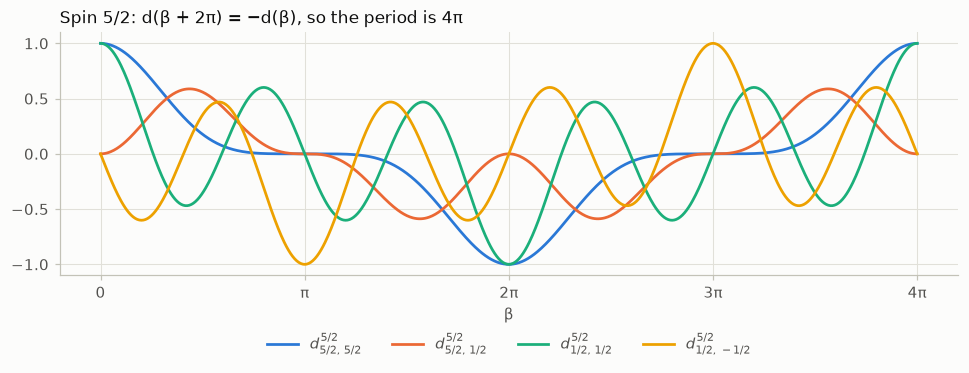

In [7]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

def style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, lw=0.7)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2)

from fractions import Fraction

def frac(x):
    return str(Fraction(x)).replace("-", "−")

j = 5/2
betas = np.linspace(0, 4 * np.pi, 801)
d_all = wigner_d(j, betas)                     # shape (801, 6, 6)

fig, ax = plt.subplots(figsize=(9, 3.6), dpi=110, facecolor=SURFACE)
for color, (mp, m) in zip(SERIES, [(5/2, 5/2), (5/2, 1/2), (1/2, 1/2), (1/2, -1/2)]):
    ax.plot(betas, d_all[:, int(mp + j), int(m + j)], color=color, lw=1.8,
            label=f"$d^{{5/2}}_{{{frac(mp)},\\,{frac(m)}}}$")
style(ax)
ax.set_xticks(np.arange(5) * np.pi, ["0", "π", "2π", "3π", "4π"])
ax.set_xlabel("β", color=INK2)
ax.set_title("Spin 5/2: d(β + 2π) = −d(β), so the period is 4π", loc="left", color=INK, fontsize=11)
legend = ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
for t in legend.get_texts():
    t.set_color(INK2)
plt.tight_layout()
plt.show()

In [8]:
x, w = np.polynomial.legendre.leggauss(64)      # nodes in x = cos(beta)
betas = np.arccos(x)
mp, m = 1/2, -3/2
spins = [3/2, 5/2, 7/2, 9/2]
column = {j: wigner_d(j, betas)[:, int(mp + j), int(m + j)] for j in spins}
gram = np.array([[np.sum(w * column[a] * column[b]) for b in spins] for a in spins])
print(gram)
print("expected diagonal 2/(2j+1):", [round(2 / (2 * j + 1), 6) for j in spins])

[[ 0.5      -0.        0.       -0.      ]
 [-0.        0.333333 -0.        0.      ]
 [ 0.       -0.        0.25     -0.      ]
 [-0.        0.       -0.        0.2     ]]
expected diagonal 2/(2j+1): [0.5, 0.333333, 0.25, 0.2]


## 5. Large spin

Nothing overflows, here for $j = 1000\tfrac12$ ($2002\times2002$). Left: signed values for $j = 30\tfrac12$, where the oscillations
can be resolved. Right: $\log_{10}|d|$ for $j = 1000\tfrac12$, showing the decay outside the classically allowed region.

(2002, 2002)  max |d d^T - 1| = 2.0272672429655358e-13


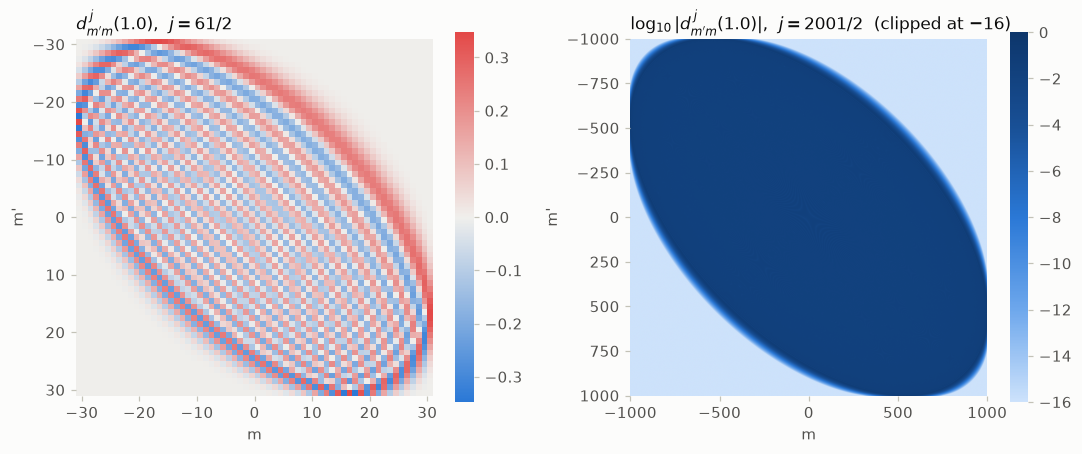

In [9]:
from matplotlib.colors import LinearSegmentedColormap

j, beta = 1000.5, 1.0
d = wigner_d(j, beta)
print(d.shape, " max |d d^T - 1| =", np.abs(d @ d.T - np.eye(len(d))).max())

diverging = LinearSegmentedColormap.from_list("blue-gray-red", ["#2a78d6", "#f0efec", "#e34948"])
sequential = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), dpi=110, facecolor=SURFACE)
j_small = 30.5
d_small = wigner_d(j_small, beta)
lim = np.abs(d_small).max()
im0 = axes[0].imshow(d_small, cmap=diverging, vmin=-lim, vmax=lim,
                     extent=[-j_small - 0.5, j_small + 0.5, j_small + 0.5, -j_small - 0.5])
with np.errstate(divide="ignore"):
    logd = np.log10(np.abs(d))
im1 = axes[1].imshow(np.clip(logd, -16, 0), cmap=sequential, vmin=-16, vmax=0, extent=[-j, j, j, -j])
for ax, im, title in [(axes[0], im0, "$d^{\\,j}_{m'm}(1.0)$,  $j = 61/2$"),
                      (axes[1], im1, "$\\log_{10}|d^{\\,j}_{m'm}(1.0)|$,  $j = 2001/2$  (clipped at −16)")]:
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("m", color=INK2)
    ax.set_ylabel("m'", color=INK2)
    ax.tick_params(colors=AXIS, labelcolor=INK2)
    for spine in ax.spines.values():
        spine.set_visible(False)
    bar = fig.colorbar(im, ax=ax, shrink=0.85)
    bar.outline.set_visible(False)
    bar.ax.tick_params(colors=AXIS, labelcolor=INK2)
plt.tight_layout()
plt.show()

Spot check against Wigner's explicit sum in `mpmath` (the cancellation needs about $0.3 \cdot 2j$ extra digits):

In [10]:
try:
    import mpmath as mpm
except ImportError:
    mpm = None
    print("pip install mpmath to run this cell")

def d_mpmath(two_j, i, k, beta):
    "Wigner's explicit sum for d^j_{m'm}, m' = i - j, m = k - j, in mpmath."
    with mpm.workdps(int(0.31 * two_j) + 25):
        c, s = mpm.cos(mpm.mpf(beta) / 2), mpm.sin(mpm.mpf(beta) / 2)
        f = mpm.factorial
        t0, t1 = max(0, k - i), min(k, two_j - i)
        term = (-1) ** (i - k + t0) * c ** (two_j + k - i - 2 * t0) * s ** (i - k + 2 * t0) \
            / (f(k - t0) * f(t0) * f(i - k + t0) * f(two_j - i - t0))
        total = term
        for t in range(t0, t1):
            term *= -(s / c) ** 2 * (k - t) * (two_j - i - t) / ((t + 1) * (i - k + t + 1))
            total += term
        return float(mpm.sqrt(f(i) * f(two_j - i) * f(k) * f(two_j - k)) * total)

if mpm is not None:
    two_j = int(2 * j)
    for mp, m in [(0.5, 0.5), (300.5, -200.5), (1000.5, 990.5), (-700.5, 650.5)]:
        i, k = int(mp + j), int(m + j)
        ref = d_mpmath(two_j, i, k, beta)
        print(f"d_{{{mp:g},{m:g}}} = {d[i, k]: .16e}   mpmath: {ref: .16e}   |diff| = {abs(d[i, k] - ref):.1e}")

d_{0.5,0.5} =  1.0270634965664809e-02   mpmath:  1.0270634965663371e-02   |diff| = 1.4e-15
d_{300.5,-200.5} =  1.5120822515420988e-02   mpmath:  1.5120822515418355e-02   |diff| = 2.6e-15
d_{1000.5,990.5} =  1.3033243108796671e-103   mpmath:  1.3033243108795444e-103   |diff| = 1.2e-116
d_{-700.5,650.5} =  6.9458536395581742e-124   mpmath:  6.9458536395571614e-124   |diff| = 1.0e-136


## 6. Threads

Matrices with $2j \ge 96$ run in parallel (if built with OpenMP), smaller ones serially. Use `num_threads=1` when you
parallelise over angles yourself. Benchmarks against other libraries are in the README.

In [11]:
import timeit

print(f"{'j':>6} {'default threads':>16} {'1 thread':>12}")
for j in [1/2, 5, 50, 200, 500]:
    number = max(3, int(2e5 / (2 * j + 1) ** 2.5))
    t_all = min(timeit.repeat(lambda: wigner_d(j, 1.1), number=number, repeat=5)) / number
    t_one = min(timeit.repeat(lambda: wigner_d(j, 1.1, num_threads=1), number=number, repeat=5)) / number
    print(f"{j:6g} {t_all * 1e3:13.4f} ms {t_one * 1e3:9.4f} ms")

     j  default threads     1 thread


   0.5        0.0014 ms    0.0014 ms
     5        0.0016 ms    0.0016 ms
    50        0.1316 ms    0.1178 ms
   200        1.7054 ms   10.3206 ms


   500       27.7895 ms  186.1587 ms
